In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, auc)

In [2]:
# Если преподаватель выдал CSV-файл, замените этот блок на:
# df = pd.read_csv('ваш_файл.csv', sep=';')

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print("Размер датасета:", df.shape)
df.head()

Размер датасета: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Проверка пропусков
print("Пропусков:", df.isnull().sum().sum())

# Признаки и целевой признак
X = df.drop('target', axis=1)
y = df['target']

# Стандартизация (важно для KNN)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_scaled.head()

Пропусков: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,1.097064,-2.073335,1.269934,0.984375,1.568466,3.283515,2.652874,2.532475,2.217515,2.255747,...,1.886690,-1.359293,2.303601,2.001237,1.307686,2.616665,2.109526,2.296076,2.750622,1.937015
1,1.829821,-0.353632,1.685955,1.908708,-0.826962,-0.487072,-0.023846,0.548144,0.001392,-0.868652,...,1.805927,-0.369203,1.535126,1.890489,-0.375612,-0.430444,-0.146749,1.087084,-0.243890,0.281190
2,1.579888,0.456187,1.566503,1.558884,0.942210,1.052926,1.363478,2.037231,0.939685,-0.398008,...,1.511870,-0.023974,1.347475,1.456285,0.527407,1.082932,0.854974,1.955000,1.152255,0.201391
3,-0.768909,0.253732,-0.592687,-0.764464,3.283553,3.402909,1.915897,1.451707,2.867383,4.910919,...,-0.281464,0.133984,-0.249939,-0.550021,3.394275,3.893397,1.989588,2.175786,6.046041,4.935010
4,1.750297,-1.151816,1.776573,1.826229,0.280372,0.539340,1.371011,1.428493,-0.009560,-0.562450,...,1.298575,-1.466770,1.338539,1.220724,0.220556,-0.313395,0.613179,0.729259,-0.868353,-0.397100


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y,
    test_size=1/3,
    random_state=42,
    stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка :", X_test.shape)

Обучающая выборка: (379, 30)
Тестовая выборка : (190, 30)


In [5]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
proba_knn = model.predict_proba(X_test)[:, 1]

print("Модель KNN обучена.")

Модель KNN обучена.


In [6]:
print("Accuracy :", round(accuracy_score(y_test, predictions), 4))
print("Precision:", round(precision_score(y_test, predictions), 4))
print("Recall   :", round(recall_score(y_test, predictions), 4))
print("F1-score :", round(f1_score(y_test, predictions), 4))

Accuracy : 0.9737
Precision: 0.9672
Recall   : 0.9916
F1-score : 0.9793


In [7]:
print(classification_report(y_test, predictions,
                            target_names=['Злокач.(0)', 'Доброкач.(1)']))

              precision    recall  f1-score   support

  Злокач.(0)       0.99      0.94      0.96        71
Доброкач.(1)       0.97      0.99      0.98       119

    accuracy                           0.97       190
   macro avg       0.98      0.97      0.97       190
weighted avg       0.97      0.97      0.97       190



In [8]:
cm = confusion_matrix(y_test, predictions)
tn, fp, fn, tp = cm.ravel()

print(cm)
print(f"Tn = {tn}", f"Fp = {fp}", f"Fn = {fn}", f"Tp = {tp}", sep='\n')

[[ 67   4]
 [  1 118]]
Tn = 67
Fp = 4
Fn = 1
Tp = 118


In [9]:
model_RF = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
model_RF.fit(X_train, y_train)

predictions_RF = model_RF.predict(X_test)
proba_RF = model_RF.predict_proba(X_test)[:, 1]

print("Модель Random Forest обучена.")

Модель Random Forest обучена.


In [10]:
print("Accuracy :", round(accuracy_score(y_test, predictions_RF), 4))
print("Precision:", round(precision_score(y_test, predictions_RF), 4))
print("Recall   :", round(recall_score(y_test, predictions_RF), 4))
print("F1-score :", round(f1_score(y_test, predictions_RF), 4))

Accuracy : 0.9526
Precision: 0.9508
Recall   : 0.9748
F1-score : 0.9627


In [11]:
print(classification_report(y_test, predictions_RF,
                            target_names=['Злокач.(0)', 'Доброкач.(1)']))

              precision    recall  f1-score   support

  Злокач.(0)       0.96      0.92      0.94        71
Доброкач.(1)       0.95      0.97      0.96       119

    accuracy                           0.95       190
   macro avg       0.95      0.95      0.95       190
weighted avg       0.95      0.95      0.95       190



In [12]:
cm_RF = confusion_matrix(y_test, predictions_RF)
tn, fp, fn, tp = cm_RF.ravel()

print(cm_RF)
print(f"Tn = {tn}", f"Fp = {fp}", f"Fn = {fn}", f"Tp = {tp}", sep='\n')

[[ 65   6]
 [  3 116]]
Tn = 65
Fp = 6
Fn = 3
Tp = 116


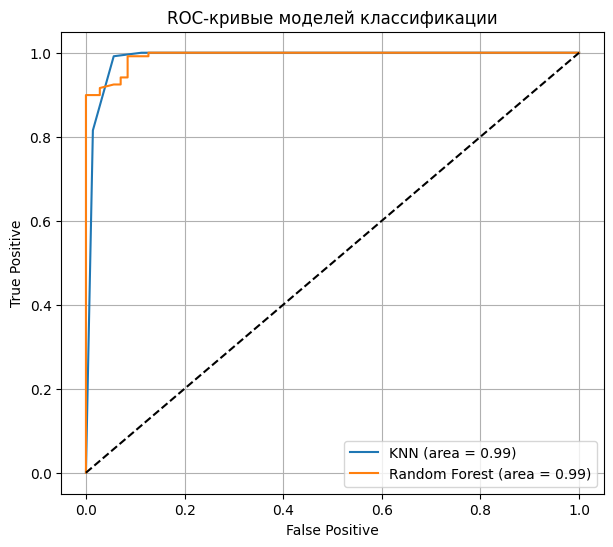

AUC KNN = 0.9873
AUC RF  = 0.9927


In [13]:
fpr_knn, tpr_knn, _ = roc_curve(y_test, proba_knn)
fpr_rf,  tpr_rf,  _ = roc_curve(y_test, proba_RF)

auc_knn = auc(fpr_knn, tpr_knn)
auc_rf  = auc(fpr_rf,  tpr_rf)

plt.figure(figsize=(7, 6))
plt.plot(fpr_knn, tpr_knn, label=f'KNN (area = {auc_knn:.2f})')
plt.plot(fpr_rf,  tpr_rf,  label=f'Random Forest (area = {auc_rf:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive')
plt.ylabel('True Positive')
plt.title('ROC-кривые моделей классификации')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"AUC KNN = {auc_knn:.4f}")
print(f"AUC RF  = {auc_rf:.4f}")

In [14]:
results = pd.DataFrame({
    'Модель': ['KNN', 'Random Forest'],
    'Accuracy': [accuracy_score(y_test, predictions),
                 accuracy_score(y_test, predictions_RF)],
    'Precision': [precision_score(y_test, predictions),
                  precision_score(y_test, predictions_RF)],
    'Recall': [recall_score(y_test, predictions),
               recall_score(y_test, predictions_RF)],
    'F1': [f1_score(y_test, predictions),
           f1_score(y_test, predictions_RF)],
    'AUC': [auc_knn, auc_rf]
})
results.round(4)

,Модель,Accuracy,Precision,Recall,F1,AUC
0,KNN,0.9737,0.9672,0.9916,0.9793,0.9873
1,Random Forest,0.9526,0.9508,0.9748,0.9627,0.9927
